# Eksploracyjna analiza danych dotyczących cen paliw w Polsce w latach 2019-2026


In [1]:
#import biblioytek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


In [9]:
#wczytanie pliku csv
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("fuel_prices.csv", sep=";")
df.head()

,productName,effectiveDate,publishFrom,value,locationName,locationSymbol,unit,productId
0,Pb95,2026-11-11T00:00:00,2026-11-11T00:00:00,5307.0,NaN,NaN,NaN,41
1,Pb95,2026-11-10T00:00:00,2026-11-10T00:00:00,5346.0,NaN,NaN,NaN,41
2,Pb95,2026-11-07T00:00:00,2026-11-07T00:00:00,5296.0,NaN,NaN,NaN,41
3,Pb95,2026-11-06T00:00:00,2026-11-06T00:00:00,5368.0,NaN,NaN,NaN,41
4,Pb95,2026-11-05T00:00:00,2026-11-05T00:00:00,5438.0,NaN,NaN,NaN,41


In [32]:
print("Wymiary zbioru:", df.shape)

df.info()

display(df.head(10))

print("\nBraki danych:")
print(df.isnull().sum())

print("\nDuplikaty:", df.duplicated().sum())

print("\nRodzaje paliw:")
print(df["productName"].unique())


Wymiary zbioru: (9715, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9715 entries, 0 to 9714
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   productName     9715 non-null   object 
 1   effectiveDate   9715 non-null   object 
 2   publishFrom     5635 non-null   object 
 3   value           9715 non-null   float64
 4   locationName    0 non-null      float64
 5   locationSymbol  0 non-null      float64
 6   unit            2576 non-null   object 
 7   productId       9715 non-null   int64  
dtypes: float64(3), int64(1), object(4)
memory usage: 607.3+ KB


,productName,effectiveDate,publishFrom,value,locationName,locationSymbol,unit,productId
0,Pb95,2026-11-11T00:00:00,2026-11-11T00:00:00,5307.0,NaN,NaN,NaN,41
1,Pb95,2026-11-10T00:00:00,2026-11-10T00:00:00,5346.0,NaN,NaN,NaN,41
2,Pb95,2026-11-07T00:00:00,2026-11-07T00:00:00,5296.0,NaN,NaN,NaN,41
3,Pb95,2026-11-06T00:00:00,2026-11-06T00:00:00,5368.0,NaN,NaN,NaN,41
4,Pb95,2026-11-05T00:00:00,2026-11-05T00:00:00,5438.0,NaN,NaN,NaN,41
5,Pb95,2026-11-04T00:00:00,2026-11-04T00:00:00,5528.0,NaN,NaN,NaN,41
6,Pb95,2026-11-03T00:00:00,2026-11-03T00:00:00,5598.0,NaN,NaN,NaN,41
7,Pb95,2026-10-31T00:00:00,2026-10-31T00:00:00,5675.0,NaN,NaN,NaN,41
8,Pb95,2026-10-30T00:00:00,2026-10-30T00:00:00,5703.0,NaN,NaN,NaN,41
9,Pb95,2026-10-29T00:00:00,2026-10-29T00:00:00,5731.0,NaN,NaN,NaN,41



Braki danych:
productName          0
effectiveDate        0
publishFrom       4080
value                0
locationName      9715
locationSymbol    9715
unit              7139
productId            0
dtype: int64

Duplikaty: 0

Rodzaje paliw:
['Pb95' 'Pb98' 'ONEkodiesel' 'ONArctic2' 'OnEkoterm']


Wstępna analiza wykazała, że zbiór danych składa się z 9715 obserwacji oraz 8 kolumn, zawierających informacje dotyczące cen produktów paliwowych, dat ich obowiązywania i publikacji oraz identyfikatorów produktów.

Na podstawie analizy kolumny productName zidentyfikowano 5 rodzajów produktów paliwowych:
- Pb95 benzyna bezołowiowa 95
- Pb98 benzyna bezołowiowa 98
- ONEkodiesel olej napędowy Ekodiesel
- ONArctic2 olej napędowy Arctic 2
- OnEkoterm olej opałowy Ekoterm

W zbiorze nie stwierdzono dokładnych duplikatów rekordów. Kolumny productName, effectiveDate, value oraz productId zawierają kompletne dane, natomiast w pozostałych kolumnach występują brakujące wartości.

In [40]:
braki = pd.DataFrame({
    "Liczba braków": df.isna().sum(),
    "Procent braków [%]": df.isna().mean() * 100
})

display(braki.round(2))

,Liczba braków,Procent braków [%]
productName,0,0.00
effectiveDate,0,0.00
publishFrom,4080,42.00
value,0,0.00
locationName,9715,100.00
locationSymbol,9715,100.00
unit,7139,73.48
productId,0,0.00


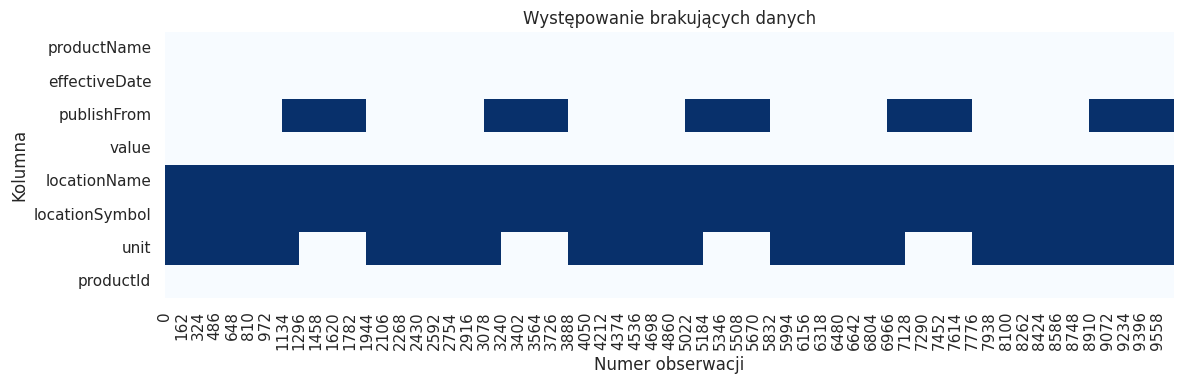

In [8]:
#wizualizacja braków

plt.figure(figsize=(12, 4))

sns.heatmap(
    df.isna().T,
    cmap="Blues",
    cbar=False,
    yticklabels=True
)

plt.title("Występowanie brakujących danych")
plt.xlabel("Numer obserwacji")
plt.ylabel("Kolumna")
plt.tight_layout()
plt.show()


Najwięcej brakujących wartości występuje w kolumnach locationName i locationSymbol, które są całkowicie puste. Znaczny odsetek braków występuje również w unit i publishFrom. Tutaj najważniejsze: kolumna value, zawierająca ceny, jest kompletna.

In [10]:
#kopia danych
df_clean = df.copy()

In [19]:
#usunięcie pustych kolumn
df_clean = df_clean.drop(columns=["locationName", "locationSymbol"])

Nie są to kolumny zbytnio znaczące dla tej analizy.

In [21]:
#konwersja dat (obejct)
df_clean["effectiveDate"] = pd.to_datetime(df_clean["effectiveDate"])

df_clean["publishFrom"] = pd.to_datetime(df_clean["publishFrom"])

#dodatkowe zmienne czasu dla ulatwienia
df_clean["rok"] = df_clean["effectiveDate"].dt.year
df_clean["miesiac"] = df_clean["effectiveDate"].dt.month

In [22]:
display(df_clean.head(10))

,productName,effectiveDate,publishFrom,value,unit,productId,rok,miesiac
0,Pb95,2026-11-11,2026-11-11,5307.0,NaN,41,2026,11
1,Pb95,2026-11-10,2026-11-10,5346.0,NaN,41,2026,11
2,Pb95,2026-11-07,2026-11-07,5296.0,NaN,41,2026,11
3,Pb95,2026-11-06,2026-11-06,5368.0,NaN,41,2026,11
4,Pb95,2026-11-05,2026-11-05,5438.0,NaN,41,2026,11
5,Pb95,2026-11-04,2026-11-04,5528.0,NaN,41,2026,11
6,Pb95,2026-11-03,2026-11-03,5598.0,NaN,41,2026,11
7,Pb95,2026-10-31,2026-10-31,5675.0,NaN,41,2026,10
8,Pb95,2026-10-30,2026-10-30,5703.0,NaN,41,2026,10
9,Pb95,2026-10-29,2026-10-29,5731.0,NaN,41,2026,10


In [13]:
# Sprawdzenie jednostek
print(df_clean["unit"].value_counts(dropna=False))

unit
NaN       7139
PLN/m3    2576
Name: count, dtype: int64


In [23]:
#uzupełnienie braków PLN/m3
df_clean["unit"] = df_clean["unit"].fillna("PLN/m3")

In [24]:
print(df_clean["unit"].value_counts(dropna=False))

unit
PLN/m3    9715
Name: count, dtype: int64


W kolumnie unit stwierdzono 7139 brakujących wartości, co stanowi ok.70%wszystkich obserwacji, zaś w pozostałych rekordach jedyną występującą jednostką była PLN/m3, więc na tej podstawie przyjęto założenie, że wszystkie ceny w zbiorze wyrażone są w PLN/m³, i uzupełniono brakujące wartości za pomocą metody fillna().

In [41]:
braki = pd.DataFrame({
    "Liczba braków": df_clean.isna().sum(),
    "Procent braków [%]": df_clean.isna().mean() * 100
})

display(braki.round(2))

,Liczba braków,Procent braków [%]
productName,0,0.0
effectiveDate,0,0.0
publishFrom,2448,42.0
value,0,0.0
unit,0,0.0
productId,0,0.0
rok,0,0.0
miesiac,0,0.0
cena_za_litr,0,0.0


In [25]:
#przeliczenie ceny z PLN/m3 na PLN/l
df_clean["cena_za_litr"] = df_clean["value"]/1000

#pokaz danych
display(df_clean[["productName", "value", "unit", "cena_za_litr"]].head(10))


,productName,value,unit,cena_za_litr
0,Pb95,5307.0,PLN/m3,5.307
1,Pb95,5346.0,PLN/m3,5.346
2,Pb95,5296.0,PLN/m3,5.296
3,Pb95,5368.0,PLN/m3,5.368
4,Pb95,5438.0,PLN/m3,5.438
5,Pb95,5528.0,PLN/m3,5.528
6,Pb95,5598.0,PLN/m3,5.598
7,Pb95,5675.0,PLN/m3,5.675
8,Pb95,5703.0,PLN/m3,5.703
9,Pb95,5731.0,PLN/m3,5.731


In [36]:
#usunięcie zbędnych danych do analzy (paliwa diesla Ecoterm oraz Artic)
df_clean = df_clean[(df_clean["productName"] != "ONArctic2") & (df_clean["productName"] != "OnEkoterm")]

#wynik
print(df_clean["productName"].value_counts())
print(df_clean.shape)

productName
Pb95           1943
Pb98           1943
ONEkodiesel    1943
Name: count, dtype: int64
(5829, 9)


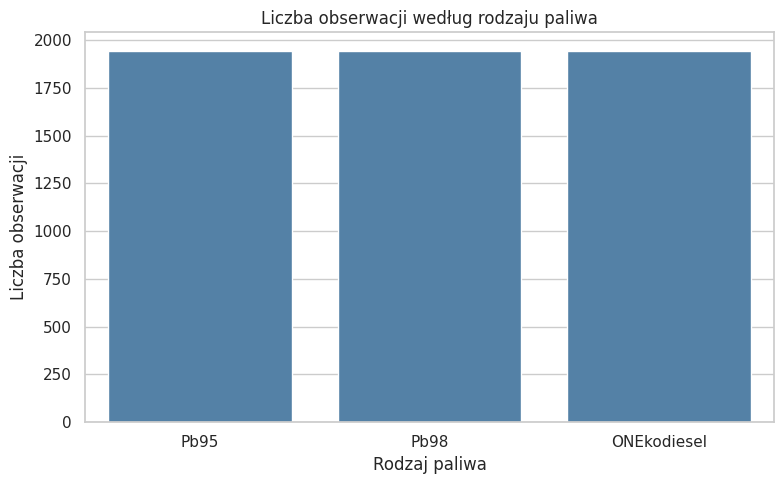

In [53]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="productName",
    color="steelblue"
)

plt.title("Liczba obserwacji według rodzaju paliwa")
plt.xlabel("Rodzaj paliwa")
plt.ylabel("Liczba obserwacji")
plt.tight_layout()
plt.show()

W początkowym zbiorze danych znajdowało się 9715 obserwacji dotyczących pięciu rodzajów produktów paliwowych: Pb95, Pb98, ON Ekodiesel, ON Arctic 2 oraz ON Ekoterm. Ze względu na przyjęte pytanie badawcze, dotyczące wpływu zmian i niepewności cen paliw na ceny produktów codziennego użytku zdecydowano się skoncentrować analizę na trzech rodzajach paliw: Pb95, Pb98 oraz ON Ekodiesel.

Wybór ten wynika z ich znaczenia dla transportu samochodowego. Z głównej analizy wyłączono ON Arctic 2, będący specjalistycznym olejem napędowym przeznaczonym do niskich temperatur, oraz Ekoterm, wykorzystywany przede wszystkim do celów grzewczych.

Po zastosowaniu filtrowania liczba obserwacji zmniejszyła się z 9715 do 5829.

In [37]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5829 entries, 0 to 5828
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   productName    5829 non-null   object        
 1   effectiveDate  5829 non-null   datetime64[ns]
 2   publishFrom    3381 non-null   datetime64[ns]
 3   value          5829 non-null   float64       
 4   unit           5829 non-null   object        
 5   productId      5829 non-null   int64         
 6   rok            5829 non-null   int32         
 7   miesiac        5829 non-null   int32         
 8   cena_za_litr   5829 non-null   float64       
dtypes: datetime64[ns](2), float64(2), int32(2), int64(1), object(2)
memory usage: 409.9+ KB


Statystyki opisowe

In [38]:
display(df_clean.describe())

,effectiveDate,publishFrom,value,productId,rok,miesiac,cena_za_litr
count,5829,3381,5829.000000,5829.000000,5829.000000,5829.000000,5829.000000
mean,2022-12-06 21:21:23.993823744,2024-08-01 22:26:43.549245696,4869.666324,42.000000,2022.441071,6.414308,4.869666
min,2019-01-01 00:00:00,2022-04-20 00:00:00,2705.000000,41.000000,2019.000000,1.000000,2.705000
25%,2020-12-15 00:00:00,2023-06-15 00:00:00,4095.000000,41.000000,2020.000000,3.000000,4.095000
50%,2022-12-07 00:00:00,2024-08-01 00:00:00,4806.000000,42.000000,2022.000000,7.000000,4.806000
75%,2024-11-23 00:00:00,2025-09-24 00:00:00,5408.000000,43.000000,2024.000000,9.000000,5.408000
max,2026-11-11 00:00:00,2026-11-11 00:00:00,8311.000000,43.000000,2026.000000,12.000000,8.311000
std,NaN,NaN,1005.873551,0.816567,2.266441,3.406674,1.005874


Po ograniczeniu zbioru danych do trzech rodzajów paliw (Pb95, Pb98 i ON Ekodiesel) liczba obserwacji wynosi 5829. Dane obejmują okres od 1 stycznia 2019 r. do 11 listopada 2026 r.

Średnia cena analizowanych paliw wynosi 4,870 PLN/l, natomiast mediana 4,806 PLN/l. Niewielka różnica między tymi wartościami może wskazywać na nieznaczną asymetrię prawostronną rozkładu cen.

Najniższa odnotowana cena wynosi 2,705 PLN/l, a najwyższa 8,311 PLN/l. Odchylenie standardowe na poziomie 1,006 PLN/l wskazuje na zróżnicowanie cen w badanym okresie.

Pierwszy kwartyl wynosi 4,095 PLN/l, a trzeci 5,408 PLN/l. Oznacza to, że środkowe 50% obserwacji znajduje się w tym przedziale cenowym.

Przedstawione statystyki dotyczą łącznie trzech rodzajów paliw.

# Statystyki cen paliw za litr

In [39]:
statystyki_paliw = df_clean.groupby("productName")["cena_za_litr"
].agg(
    liczba_obserwacji="count",
    srednia="mean",
    mediana="median",
    odchylenie_std="std",
    minimum="min",
    maksimum="max"
)

display(statystyki_paliw.round(3))


,liczba_obserwacji,srednia,mediana,odchylenie_std,minimum,maksimum
productName,,,,,,
ONEkodiesel,1943,4.892,4.769,1.088,2.876,7.704
Pb95,1943,4.673,4.607,0.876,2.705,7.519
Pb98,1943,5.044,4.994,1.008,2.958,8.311


Najwyższą średnią cenę w badanym okresie odnotowano dla benzyny Pb98 (5,044 PLN/l), natomiast najniższą dla Pb95 (4,673 PLN/l). Średnia cena oleju napędowego ON Ekodiesel wyniosła 4,892 PLN/l.

Największym odchyleniem standardowym charakteryzował się ON Ekodiesel (1,088 PLN/l), co wskazuje na największe zróżnicowanie jego cen w analizowanym okresie. Najmniejsze odchylenie standardowe wystąpiło dla Pb95 (0,876 PLN/l).

Wyniki wskazują, że olej napędowy charakteryzował się największą bezwzględną zmiennością poziomu cen spośród analizowanych paliw. Jest to istotne w kontekście pytania badawczego, ponieważ zmiany kosztów oleju napędowego mogą oddziaływać na koszty transportu i dystrybucji produktów codziennego użytku.

# Histogram Rozkładu cen paliw



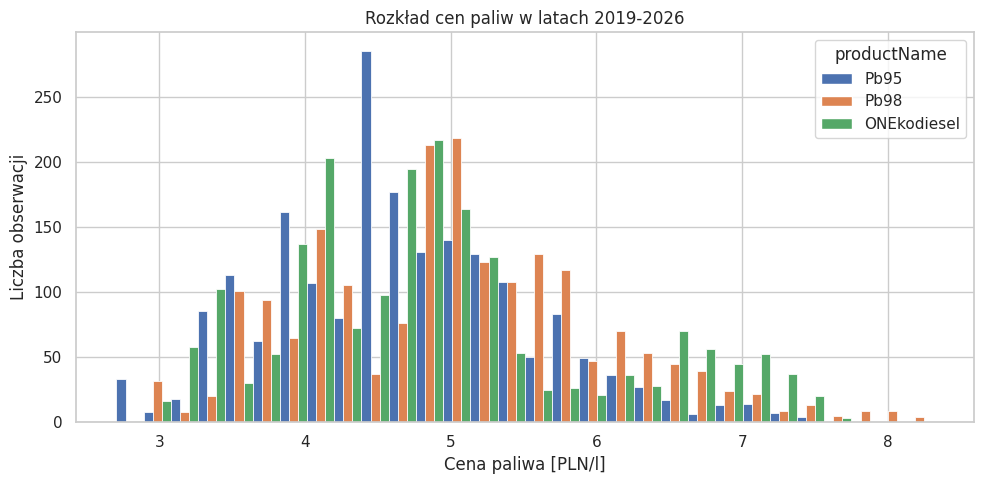

In [48]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="cena_za_litr",
    hue="productName",
    bins=30,
    multiple="dodge",
    alpha=1
)

plt.title("Rozkład cen paliw w latach 2019-2026")
plt.xlabel("Cena paliwa [PLN/l]")
plt.ylabel("Liczba obserwacji")
plt.tight_layout()
plt.show()


Histogram przedstawia rozkład cen trzech rodzajów paliw w latach 2019–2026. Największa koncentracja obserwacji występuje w przedziale około 4-5,5 PLN/l, przy czym rozkład Pb98 jest przesunięty w kierunku wyższych cen w porównaniu z Pb95.

Ceny ON Ekodiesel charakteryzują się większym rozproszeniem, co jest zgodne z wcześniej obliczonym najwyższym odchyleniem standardowym (1,088 PLN/l). Dla wszystkich trzech paliw widoczne są również obserwacje w wyższych przedziałach cenowych, wskazujące na okresy podwyższonych cen.

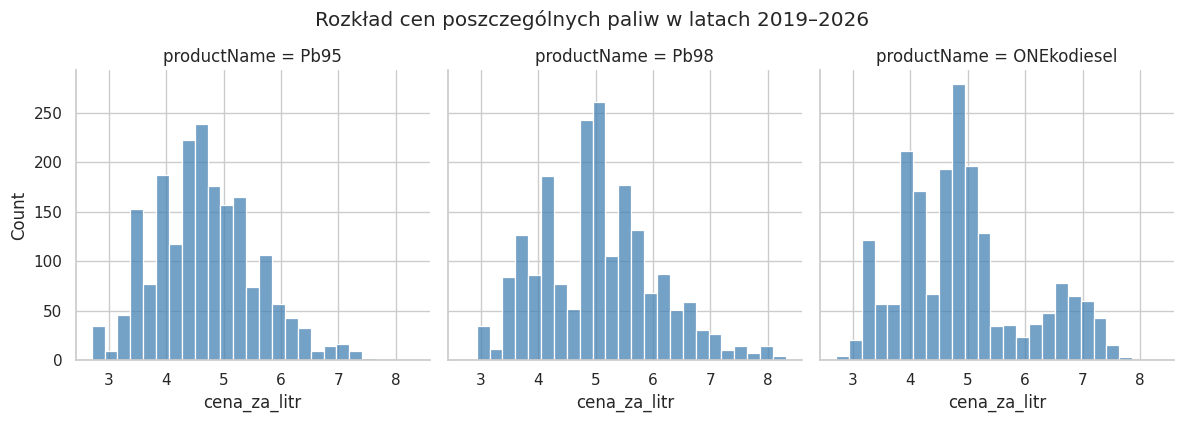

In [47]:
sns.displot(
    data=df_clean,
    x="cena_za_litr",
    col="productName",
    bins=25,
    height=4,
    aspect=1,
    color="steelblue"
)

plt.suptitle(
    "Rozkład cen poszczególnych paliw w latach 2019-2026",
    y=1.05
)

plt.show()


# Boxplot - porównanie rozkładów cen

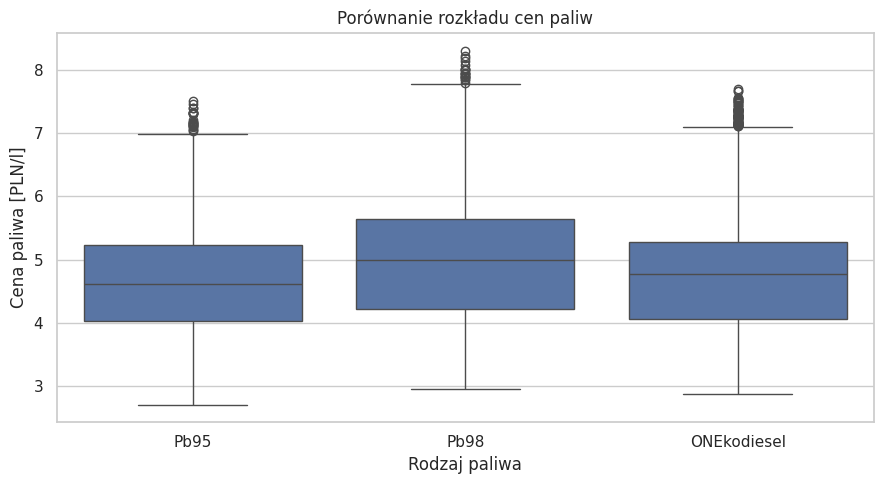

In [43]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="productName",
    y="cena_za_litr"
)

plt.title("Porównanie rozkładu cen paliw")
plt.xlabel("Rodzaj paliwa")
plt.ylabel("Cena paliwa [PLN/l]")
plt.tight_layout()
plt.show()


Wykres pudełkowy przedstawia zróżnicowanie cen trzech rodzajów paliw w latach 2019-2026. Najwyższą medianą charakteryzuje się benzyna Pb98 (4,994 PLN/l), natomiast najniższą Pb95 (4,607 PLN/l).

ON Ekodiesel wykazuje największe odchylenie standardowe cen spośród analizowanych paliw (1,088 PLN/l), co wskazuje na ich większe zróżnicowanie w badanym okresie.

Dla wszystkich trzech rodzajów paliw widoczne są potencjalne wartości odstające po stronie wysokich cen, które mogą odpowiadać okresom znacznych podwyżek.

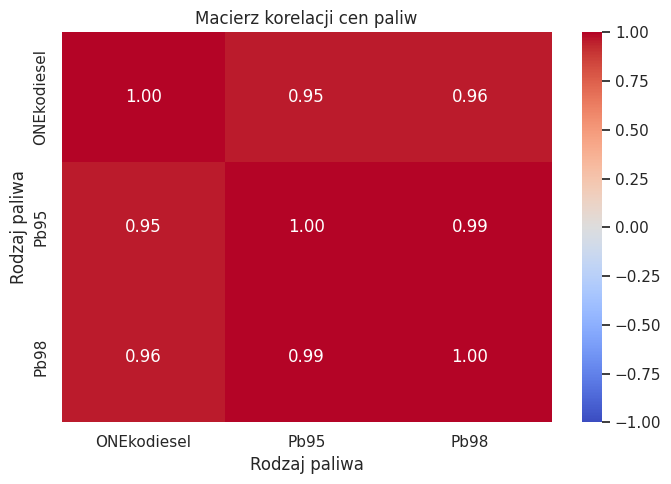

In [44]:
#przygotowanie tabeli z cenami trzech paliw
ceny = df_clean.pivot(index="effectiveDate", columns="productName", values="cena_za_litr")

#macierz korelacji
korelacje = ceny.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
korelacje,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Macierz korelacji cen paliw")
plt.xlabel("Rodzaj paliwa")
plt.ylabel("Rodzaj paliwa")
plt.tight_layout()
plt.show()


Macierz korelacji wskazuje na bardzo silne dodatnie zależności liniowe między poziomami cen wszystkich analizowanych rodzajów paliw. Najwyższą korelację zaobserwowano między benzyną Pb95 i Pb98 (r = 0,99), natomiast korelacje oleju napędowego ON Ekodiesel z benzynami wyniosły odpowiednio 0,95 i 0,96.

Wyniki sugerują, że ceny analizowanych paliw wykazywały podobne tendencje w badanym okresie, co może wynikać z oddziaływania wspólnych czynników rynkowych. Należy jednak pamiętać, że korelacja nie oznacza związku przyczynowo-skutkowego, a wysokie współczynniki dla poziomów cen nie muszą oznaczać równie silnych korelacji ich krótkookresowych zmian.

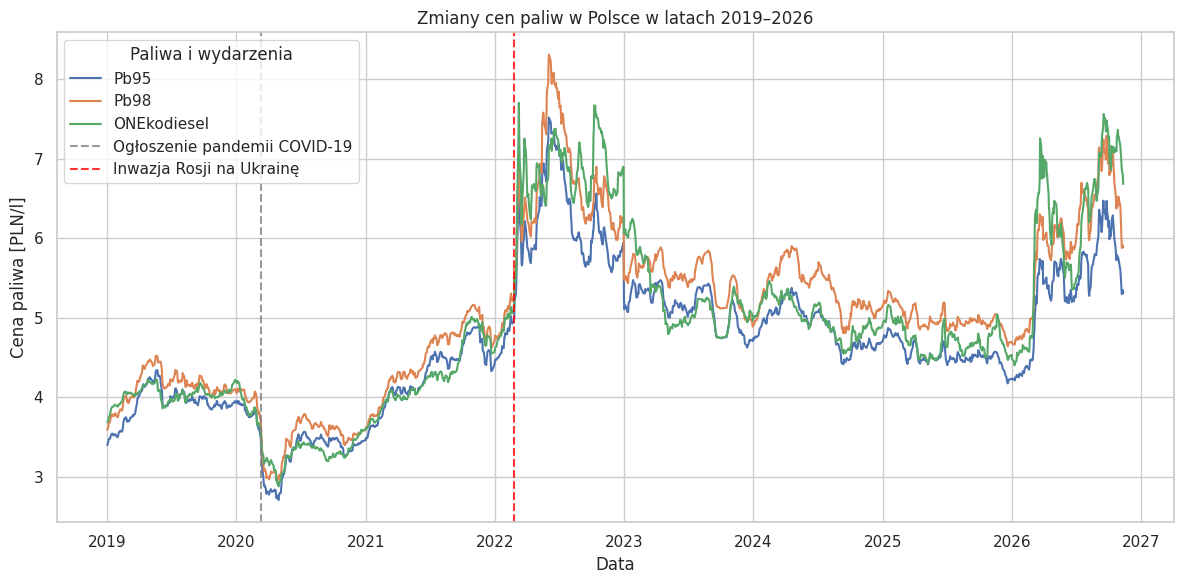

In [51]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_clean,
    x="effectiveDate",
    y="cena_za_litr",
    hue="productName"
)

plt.title("Zmiany cen paliw w Polsce w latach 2019–2026")
plt.xlabel("Data")
plt.ylabel("Cena paliwa [PLN/l]")
plt.legend(title="Rodzaj paliwa")
plt.tight_layout()

plt.axvline(
    pd.Timestamp("2020-03-11"),
    color="gray",
    linestyle="--",
    alpha=0.8,
    label="Ogłoszenie pandemii COVID-19"
)

plt.axvline(
    pd.Timestamp("2022-02-24"),
    color="red",
    linestyle="--",
    alpha=0.8,
    label="Inwazja Rosji na Ukrainę"
)

plt.legend(title="Paliwa i wydarzenia")


plt.show()


Wykres przedstawia zmiany cen trzech rodzajów paliw: Pb95, Pb98 oraz ON Ekodiesel w latach 2019-2026. Zaobserwowano silną dodatnią współzmienność cen wszystkich trzech produktów, co jest zgodne z wcześniej obliczonymi wysokimi współczynnikami korelacji. W analizowanym okresie można wyróżnić kilka etapów, charakteryzujących się odmienną dynamiką zmian cen.

Pierwszy istotny spadek cen nastąpił w 2020 roku, co można powiązać z wybuchem pandemii COVID-19. Wprowadzone ograniczenia przemieszczania się, zmniejszenie aktywności gospodarczej oraz spadek zapotrzebowania na transport doprowadziły do ograniczenia światowego popytu na ropę naftową. W kolejnych miesiącach, wraz ze stopniowym znoszeniem ograniczeń i odbudową gospodarki, ceny paliw zaczęły ponownie rosnąć.

W 2021 roku zaobserwowano wyraźny trend wzrostowy, związany z ożywieniem gospodarczym po pandemii oraz rosnącym zapotrzebowaniem na surowce energetyczne. Tendencja ta nasiliła się w 2022 roku, kiedy nastąpił szczególnie gwałtowny wzrost cen wszystkich analizowanych paliw.

Najsilniejsze wzrosty cen wystąpiły w 2022 roku, co zbiegło się z rozpoczęciem pełnoskalowej inwazji Rosji na Ukrainę 24 lutego 2022 roku. Konflikt wywołał znaczną niepewność na światowych rynkach energetycznych, obawy o ciągłość dostaw ropy oraz wzrost cen surowców. W konsekwencji ceny analizowanych paliw osiągnęły najwyższe poziomy w całym badanym okresie.

W latach 2023–2025 nastąpił spadek cen i ich częściowa stabilizacja, chociaż nadal występowały okresowe wahania. Zmiany te można wiązać między innymi z dostosowaniem światowych rynków energetycznych do nowej sytuacji geopolitycznej oraz zmianami cen ropy i kursów walutowych.

W 2026 roku widoczny jest ponowny gwałtowny wzrost cen i zwiększenie ich niestabilności. Zjawisko to można rozpatrywać w kontekście napięć geopolitycznych na Bliskim Wschodzie, zagrożeń dla międzynarodowych dostaw ropy oraz działań regulacyjnych podejmowanych na polskim rynku paliw.

Z punktu widzenia przyjętego pytania badawczego szczególnie istotne są okresy gwałtownych wzrostów cen w latach 2022 i 2026. Wzrost kosztów paliw, zwłaszcza oleju napędowego wykorzystywanego w transporcie towarowym, może prowadzić do zwiększenia kosztów przewozu i dystrybucji produktów codziennego użytku. Może to wywierać presję na ceny konsumpcyjne, a w konsekwencji ograniczać siłę nabywczą gospodarstw domowych.

In [46]:
#średnie ceny miesięczne
ceny_miesieczne = ceny.resample("MS").mean()

#procentowe zmiany cen miesiąc do miesiąca
zmiany_proc = ceny_miesieczne.pct_change() * 100

display(zmiany_proc.head(10))

#zmienność zmian procentowych
print("Odchylenie standardowe miesięcznych zmian [%]:")
display(zmiany_proc.std().round(2))

productName,ONEkodiesel,Pb95,Pb98
effectiveDate,,,
2019-01-01,NaN,NaN,NaN
2019-02-01,3.962199,4.042048,4.592732
2019-03-01,1.263487,4.610918,3.597978
2019-04-01,2.434961,8.417850,7.681127
2019-05-01,0.441223,2.962576,2.180584
2019-06-01,-5.784130,-7.264368,-6.088365
2019-07-01,1.958827,2.101289,1.391492
2019-08-01,0.679312,-0.862356,-1.312405
2019-09-01,2.192141,-0.742667,0.063520


Odchylenie standardowe miesięcznych zmian [%]:


,0
productName,
ONEkodiesel,6.98
Pb95,6.04
Pb98,5.96


W celu oceny niestabilności cen paliw obliczono średnie miesięczne ceny poszczególnych produktów, a następnie ich procentowe zmiany miesiąc do miesiąca. Na podstawie otrzymanych zmian wyznaczono odchylenie standardowe, które wykorzystano jako miarę zmienności cen w badanym okresie.

Najwyższą zmiennością miesięcznych zmian cen charakteryzował się ON Ekodiesel (6,98 p.p.), natomiast dla Pb95 i Pb98 wartości te wyniosły odpowiednio 6,04 i 5,96 p.p. Wyniki wskazują, że ceny oleju napędowego wykazywały większą niestabilność krótkookresową niż ceny benzyn.

Jest to szczególnie istotne w kontekście pytania badawczego, ponieważ wahania cen oleju napędowego mogą zwiększać niepewność kosztów transportu i dystrybucji towarów, a pośrednio również wpływać na ceny produktów codziennego użytku. Potwierdzenie tych zależności wymaga jednak dalszej analizy z wykorzystaniem danych o cenach produktów konsumpcyjnych.

# Źródła



1.   https://www.gov.pl/web/energia/maksymalna-cena-detaliczna-paliw-obowiazujaca-w-dniach-7-9-listopada-2026-r - ceny paliw 2026 r.
2. https://popihn.pl/wp-content/uploads/2026/05/RAPORT-ZA-ROK-2025-ENG.pdf - raport o polskim rynku paliw 2025 r.
3. https://www.ecb.europa.eu/press/economic-bulletin/focus/2022/html/ecb.ebbox202204_01~68ef3c3dc6.en.html - wpływ wojny na Ukrainie
4. https://www.iea.org/topics/2022-energy-crisis - krzyys energetyczny 2022 r.
5. https://www.eia.gov/todayinenergy/detail.php - załamanie rynku ropy 2-2- r.

